# 클래스 분포
train / val / test별 클래스의 **객체 수(YOLO 라벨 행 수)**를 텍스트 표와 막대그래프로 표시합니다. 한 이미지에 객체가 여러 개 있으면 각각 집계합니다.


Object counts (label boxes)
       general  plastic  can  glass
train     1052      678  110     86
val        317      343   28     38
test       515      658   49     50

Split totals
train    1926
val       726
test     1272


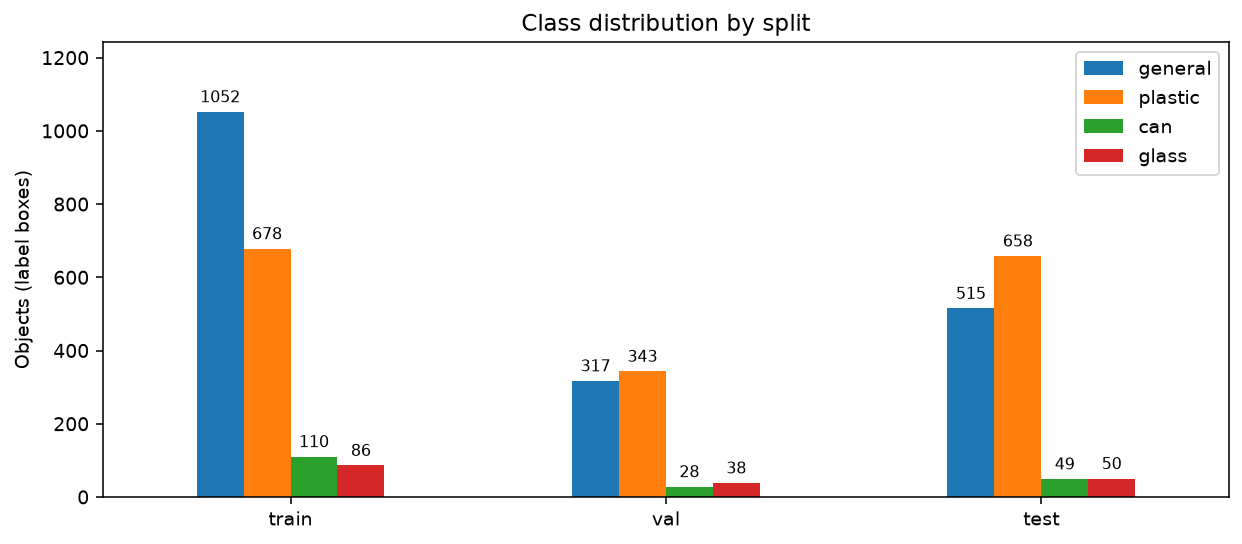

In [1]:
from pathlib import Path
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

root = Path(r"C:\Users\qotjd\Desktop\yolo_20261111_163448_cleaned")
classes = root.joinpath("classes.txt").read_text().splitlines()
counts = {s: Counter(int(line.split()[0]) for f in (root / "labels" / s).glob("*.txt")
                     for line in f.read_text().splitlines() if line.strip()) for s in ["train", "val", "test"]}
df = pd.DataFrame({s: [c[i] for i in range(len(classes))] for s, c in counts.items()}, index=classes).T
print("Object counts (label boxes)\n" + df.to_string() + "\n\nSplit totals\n" + df.sum(axis=1).to_string())
ax = df.plot.bar(figsize=(9, 4), rot=0, ylabel="Objects (label boxes)", title="Class distribution by split")
for bars in ax.containers:
    ax.bar_label(bars, padding=3, fontsize=8)
ax.set_ylim(0, df.to_numpy().max() * 1.18)
plt.tight_layout()
plt.show()
